# Q4. Predicting Reported Injury from Time of Day and Calendar Data

**Course** — CSC17104 · Programming for Data Science  
**Group** — Group 14 · Tam Khuyển  
**Question owner** — Lê Việt Hải (24127029)  
**Scope** — Machine learning · 2018–2024 comparison period  
**Dataset** — Traffic Accidents, Chicago (Kaggle snapshot)  
**Prerequisite** — Run [notebook 01](01_collection_exploration.ipynb) to generate `data/processed/traffic_accidents_clean.csv`.  
**Assistance log** — [LLM_USAGE.md](../LLM_USAGE.md)

## Introduction

**Research questions**

- **Q4** — How well can the clock and calendar information available at intake distinguish crashes with a reported injury?

**Motivation**

Emergency-dispatch analysts can use this retrospective comparison to decide whether richer intake data would be worth collecting for a follow-up study.

**Analysis plan**

Compare a majority baseline and two tuned models using chronological validation and a 2023–2024 holdout. The recorded crash timestamp approximates intake time. The dataset contains no dispatch records or triage outcomes.

## Cohort, target and information available at intake

- The target is `has_injury` from notebook 01, defined as `injuries_total > 0`. One row represents one recorded crash.
- The model inputs are hour, weekday and month. These can be derived from a timestamp at intake. In the snapshot they describe the time of the crash, which may differ from the time the call is received.
- Excluded outcome-related fields include `crash_type`, `most_severe_injury`, `damage`, all `injuries_*` columns and the derived injury flags. The raw timestamp and year are used for ordering and splitting.
- The table has no evidence that police-coded details were available at intake. The model excludes cause, collision type, unit count, traffic controls, intersection status, road and lighting conditions, and reported weather. Collision type is used only for post-evaluation error analysis.
- Train on 2018-2022 and reserve 2023-2024 for one final evaluation. Early years and the partial 2025 period are excluded using the shared full-calendar comparison window.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analysis_utils import load_processed, restrict

sns.set_theme(style="whitegrid")
crashes = load_processed(ROOT)
period = restrict(crashes, crashes["crash_year"].between(2018, 2024), "Use 2018-2024 comparison years")

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay, accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from threadpoolctl import threadpool_limits

period = period.sort_values("crash_date", kind="stable").reset_index(drop=True)
train = restrict(period, period["crash_year"].le(2022), "Training years 2018-2022")
holdout = restrict(period, period["crash_year"].ge(2023), "Holdout years 2023-2024")
assert len(train) + len(holdout) == len(period)
assert train["crash_date"].max() < holdout["crash_date"].min()

features = ["crash_hour", "crash_day_of_week", "crash_month"]
X_train = train[features]
y_train = train["has_injury"].astype(int)
year_train = train["crash_year"].to_numpy()
print(f"Training class prevalence: {y_train.mean():.2%}")
print("Predictors:", ", ".join(features))

data/processed/traffic_accidents_clean.csv: 209,275 rows, 29 columns
Use 2018-2024 comparison years: 209,275 -> 181,051 rows (28,224 excluded)
Training years 2018-2022: 181,051 -> 129,393 rows (51,658 excluded)
Holdout years 2023-2024: 181,051 -> 51,658 rows (129,393 excluded)
Training class prevalence: 26.49%
Predictors: crash_hour, crash_day_of_week, crash_month


## Model selection, tuning and threshold

**Metric.** Use average precision (AP), a summary of the precision–recall curve. At the relevant prevalence, a model can score well on accuracy by always predicting no injury while missing every injury. AP measures ranking quality for the positive class, and a constant score has AP equal to the positive prevalence.

**Validation.** Tune logistic regression and histogram gradient boosting on expanding training folds. Validation years are 2020, 2021, and 2022, with each fit using only earlier years. The model with the highest mean validation AP is selected before reading the holdout outcomes. All imputing and one-hot encoding are fitted inside a pipeline. The majority-class dummy is a reference.

**Operating point.** For each tuned model, collect predictions on the three validation years from fits on earlier years. Select the highest-precision cutoff among those with validation recall of at least 80%. This is an illustrative course comparison for a setting where false negatives matter, with no operational threshold determined from this dataset. The validation cutoff reuses the folds used for model selection. The held-out period is reserved for evaluating the resulting policy.

In [3]:
def make_pipeline(estimator):
    clock_categories = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessing = ColumnTransformer([("clock", clock_categories, features)])
    return Pipeline([("preprocess", preprocessing), ("model", estimator)])


validation_years = [2020, 2021, 2022]
folds = [
    (np.flatnonzero(year_train < year), np.flatnonzero(year_train == year))
    for year in validation_years
]
display(pd.DataFrame([
    {"validation_year": year, "training_rows": len(fit_idx), "validation_rows": len(val_idx)}
    for year, (fit_idx, val_idx) in zip(validation_years, folds)
]))

candidates = {
    "Logistic regression": (
        LogisticRegression(max_iter=600),
        {"model__C": [0.1, 1.0, 10.0]},
    ),
    "Histogram gradient boosting": (
        HistGradientBoostingClassifier(random_state=42, early_stopping=False),
        {"model__max_iter": [40, 80], "model__max_leaf_nodes": [7, 15], "model__l2_regularization": [1.0]},
    ),
}
searches = {}
with threadpool_limits(limits=2):
    for name, (estimator, grid) in candidates.items():
        search = GridSearchCV(
            make_pipeline(estimator), grid, scoring="average_precision", cv=folds,
            n_jobs=1, refit=True, error_score="raise",
        )
        searches[name] = search.fit(X_train, y_train)

validation_results = pd.DataFrame([
    {"model": name, "mean_validation_ap": search.best_score_, "selected_parameters": search.best_params_}
    for name, search in searches.items()
]).sort_values("mean_validation_ap", ascending=False)
display(validation_results)
winner = validation_results.iloc[0]["model"]
print(f"Selected before holdout evaluation: {winner}")

,validation_year,training_rows,validation_rows
0,2020,55387,22777
1,2021,78164,25689
2,2022,103853,25540


,model,mean_validation_ap,selected_parameters
0,Logistic regression,0.303825,{'model__C': 1.0}
1,Histogram gradient boosting,0.302827,"{'model__l2_regularization': 1.0, 'model__max_..."


Selected before holdout evaluation: Logistic regression


In [4]:
def choose_threshold(labels, probabilities, recall_goal=0.80):
    precision, recall, thresholds = precision_recall_curve(labels, probabilities)
    feasible = np.flatnonzero(recall[:-1] >= recall_goal)
    best = max(feasible, key=lambda i: (precision[i], thresholds[i]))
    return thresholds[best], precision[best], recall[best]


threshold_rows = []
with threadpool_limits(limits=2):
    for name, search in searches.items():
        validation_probs = []
        validation_labels = []
        for fit_idx, val_idx in folds:
            model = clone(search.best_estimator_).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
            validation_probs.extend(model.predict_proba(X_train.iloc[val_idx])[:, 1])
            validation_labels.extend(y_train.iloc[val_idx])
        threshold, precision, recall = choose_threshold(validation_labels, validation_probs)
        threshold_rows.append({
            "model": name, "threshold": threshold,
            "validation_precision": precision, "validation_recall": recall,
        })
threshold_table = pd.DataFrame(threshold_rows).set_index("model")
display(threshold_table.round(4))

,threshold,validation_precision,validation_recall
model,,,
Logistic regression,0.2369,0.2821,0.8050
Histogram gradient boosting,0.2466,0.2820,0.8002


## Frozen holdout comparison

The table compares the constant majority-class baseline and the two tuned models on 2023-2024. Candidate predictions use the cutoffs fixed above. Alerts per 100 records approximate the workload of reviewing positive flags. The threshold-free AP and the false-negative and alert counts help evaluate the trade-off at the chosen cutoff.

Holdout: 51,658 crashes; injury prevalence 28.60%


,average_precision,threshold,accuracy,precision,recall,f1,true_positive,false_negative,true_negative,false_positive,alerts_per_100_crashes
model,,,,,,,,,,,
Majority baseline,0.2860,NaN,0.7140,0.0000,0.0000,0.0000,0,14775,36883,0,0.0000
Logistic regression,0.3217,0.2369,0.3633,0.2932,0.8694,0.4385,12845,1930,5923,30960,84.7981
Histogram gradient boosting,0.3209,0.2466,0.3610,0.2929,0.8728,0.4386,12895,1880,5755,31128,85.2201


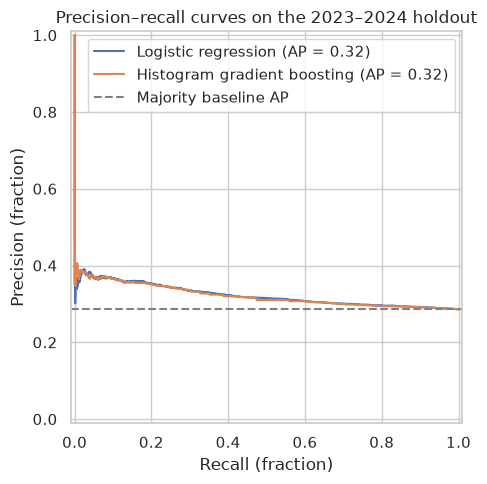

In [5]:
X_holdout = holdout[features]
y_holdout = holdout["has_injury"].astype(int)
dummy = make_pipeline(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
models = {"Majority baseline": dummy}
models.update({name: search.best_estimator_ for name, search in searches.items()})

scores = {}
predicted = {}
holdout_rows = []
with threadpool_limits(limits=2):
    for name, model in models.items():
        score = model.predict_proba(X_holdout)[:, 1]
        if name == "Majority baseline":
            threshold = np.nan
            prediction = model.predict(X_holdout)
        else:
            threshold = threshold_table.loc[name, "threshold"]
            prediction = (score >= threshold).astype(int)
        scores[name] = score
        predicted[name] = prediction
        tn, fp, fn, tp = confusion_matrix(y_holdout, prediction, labels=[0, 1]).ravel()
        holdout_rows.append({
            "model": name, "average_precision": average_precision_score(y_holdout, score),
            "threshold": threshold, "accuracy": accuracy_score(y_holdout, prediction),
            "precision": precision_score(y_holdout, prediction, zero_division=0),
            "recall": recall_score(y_holdout, prediction, zero_division=0),
            "f1": f1_score(y_holdout, prediction, zero_division=0),
            "true_positive": tp, "false_negative": fn, "true_negative": tn, "false_positive": fp,
            "alerts_per_100_crashes": 100 * prediction.mean(),
        })
holdout_results = pd.DataFrame(holdout_rows).set_index("model")
print(f"Holdout: {len(holdout):,} crashes; injury prevalence {y_holdout.mean():.2%}")
display(holdout_results.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
for name in candidates:
    PrecisionRecallDisplay.from_predictions(y_holdout, scores[name], name=name, ax=ax)
ax.axhline(y_holdout.mean(), linestyle="--", color="gray", label="Majority baseline AP")
ax.set(title="Precision–recall curves on the 2023–2024 holdout", xlabel="Recall (fraction)", ylabel="Precision (fraction)")
ax.legend()
fig.tight_layout()
plt.show()

## Where the selected model missed injuries

Subgroups are evaluated after freezing the model and threshold. The tables show missing injuries among actual injury cases and false alerts among actual no-injury cases. Collision types with fewer than 100 injury records are excluded from the plot to retain a usable denominator. Collision type is a retrospective diagnostic only.

,crashes,injuries,misses,false_alerts,missed_pct_of_injuries,false_alert_pct_of_no_injury
time_period,,,,,,
Afternoon,20671,5560,1428,10716,25.68,70.92
Evening,12530,3816,134,8343,3.51,95.74
Morning,13689,3708,368,8830,9.92,88.47
Night,4768,1691,0,3071,0.00,99.81


Collision types displayed: 18 total; only types with at least 100 injuries are plotted.


,crashes,injuries,misses,false_alerts,missed_pct_of_injuries,false_alert_pct_of_no_injury
first_crash_type,,,,,,
PEDALCYCLIST,1535,1176,79,325,6.72,90.53
OTHER OBJECT,238,108,8,116,7.41,89.23
PARKED MOTOR VEHICLE,1298,119,10,1003,8.40,85.07
HEAD ON,451,200,19,220,9.50,87.65
FIXED OBJECT,1051,304,30,682,9.87,91.30
ANGLE,13626,4829,585,7348,12.11,83.53
TURNING,16291,3780,496,10440,13.12,83.45
SIDESWIPE SAME DIRECTION,4942,374,51,3788,13.64,82.92
REAR END,8707,1577,240,5992,15.22,84.04


Holdout examples: injury cases missed by the selected model: 51,658 -> 1,930 rows (49,728 excluded)


,time_period,crash_hour,first_crash_type,score,actual_injury,flag
131497,Afternoon,12,PEDESTRIAN,0.1914,1,0
132909,Afternoon,12,ANGLE,0.1914,1,0
157287,Afternoon,12,REAR END,0.1914,1,0
158131,Afternoon,12,ANGLE,0.1914,1,0
131500,Afternoon,13,ANGLE,0.1949,1,0


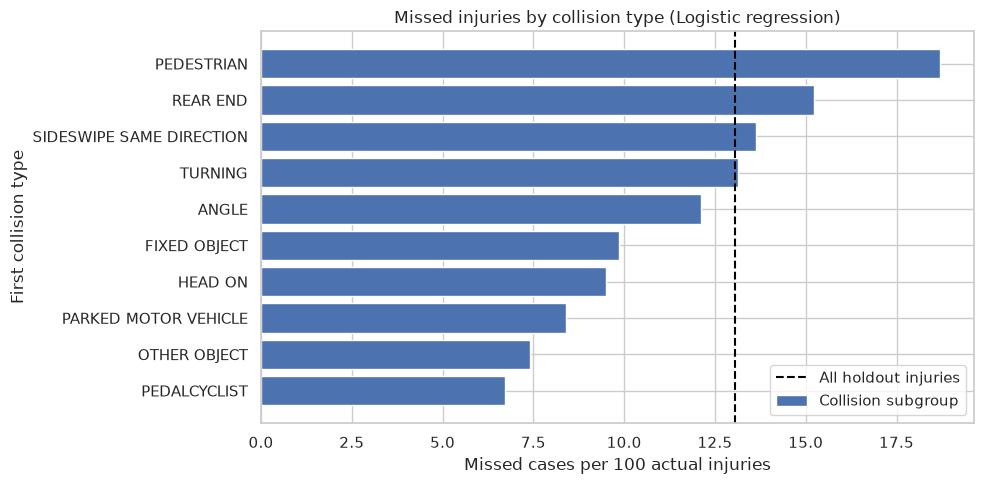

In [6]:
errors = holdout[["time_period", "crash_hour", "first_crash_type"]].copy()
errors["actual_injury"] = y_holdout.to_numpy()
errors["flag"] = predicted[winner]
errors["score"] = scores[winner]
errors["missed"] = (errors["actual_injury"] == 1) & (errors["flag"] == 0)
errors["false_alert"] = (errors["actual_injury"] == 0) & (errors["flag"] == 1)


def summarize_errors(group):
    result = errors.groupby(group, observed=True).agg(
        crashes=("actual_injury", "size"), injuries=("actual_injury", "sum"),
        misses=("missed", "sum"), false_alerts=("false_alert", "sum"),
    )
    result["missed_pct_of_injuries"] = 100 * result["misses"] / result["injuries"]
    result["false_alert_pct_of_no_injury"] = 100 * result["false_alerts"] / (result["crashes"] - result["injuries"])
    return result


time_errors = summarize_errors("time_period")
collision_errors = summarize_errors("first_crash_type")
display(time_errors.round(2))
print(f"Collision types displayed: {len(collision_errors)} total; only types with at least 100 injuries are plotted.")
collision_plot = collision_errors.loc[collision_errors["injuries"].ge(100)].sort_values("missed_pct_of_injuries")
display(collision_plot.round(2))

misses = restrict(errors, errors["missed"], "Holdout examples: injury cases missed by the selected model")
display(misses.nsmallest(5, "score")[["time_period", "crash_hour", "first_crash_type", "score", "actual_injury", "flag"]].round(4))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(collision_plot.index, collision_plot["missed_pct_of_injuries"], label="Collision subgroup")
overall_miss = 100 * (1 - holdout_results.loc[winner, "recall"])
ax.axvline(overall_miss, color="black", linestyle="--", label="All holdout injuries")
ax.set(title=f"Missed injuries by collision type ({winner})", xlabel="Missed cases per 100 actual injuries", ylabel="First collision type")
ax.legend()
fig.tight_layout()
plt.show()

## Which inputs affect ranking?

Permutation importance is calculated on the last validation year (2022), using a clone of the selected model fitted only on 2018-2021. Each input is shuffled ten times and the change in AP is measured. The error bars are standard deviations across shuffles. Importance reflects predictive value in this model and can be affected by dependence between calendar inputs.

,feature,mean_ap_drop,std_ap_drop
1,crash_day_of_week,0.00134,0.00059
2,crash_month,0.00840,0.00241
0,crash_hour,0.02709,0.00301


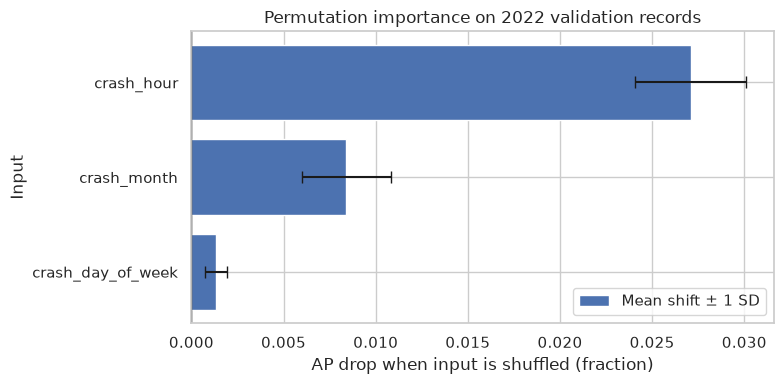

In [ ]:
fit_idx, val_idx = folds[-1]
with threadpool_limits(limits=2):
    explain_model = clone(searches[winner].best_estimator_).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
    perm = permutation_importance(
        explain_model, X_train.iloc[val_idx], y_train.iloc[val_idx],
        scoring="average_precision", n_repeats=10, random_state=42, n_jobs=1,
    )
importance = pd.DataFrame({
    "feature": features, "mean_ap_drop": perm.importances_mean, "std_ap_drop": perm.importances_std,
}).sort_values("mean_ap_drop")
display(importance.round(5))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance["feature"], importance["mean_ap_drop"], xerr=importance["std_ap_drop"], capsize=4, label="Mean shift ± 1 SD")
ax.axvline(0, color="black", linewidth=1)
ax.set(title="Permutation importance on 2022 validation records", xlabel="AP drop when input is shuffled (fraction)", ylabel="Input")
ax.legend()
fig.tight_layout()
plt.show()

## Results and answer

The analysis tested whether hour of day, day of week, and month could help identify crashes involving a reported injury. The models were trained and tuned on records from 2018–2022 and evaluated on 51,658 crashes from 2023–2024. Logistic regression was selected before the final evaluation because it had the highest validation AP. On the held-out data, it achieved an AP of 0.3217, compared with 0.3209 for histogram gradient boosting and 0.2860 for the majority-class baseline. The baseline reached 71.40% accuracy by predicting no injury for every crash, which meant it missed every injury case.

At the threshold of 0.2369 selected on validation data, logistic regression detected 86.94% of crashes involving injury. Its precision was 29.32%, meaning that fewer than three in ten alerts corresponded to an actual injury. The model flagged about 85 out of every 100 crashes, generated 30,960 false alerts, and missed 1,930 injury cases.

The model missed 25.68% of afternoon injury cases and 3.51% of evening injury cases. It detected every nighttime injury case in the test set while flagging 99.81% of nighttime crashes without injuries. In the permutation analysis on 2022 validation data, shuffling the hour of day caused the largest drop in AP, followed by shuffling the month and the day of week.

Overall, clock and calendar information provided some ability to rank crashes by injury risk. The modest improvement in ranking and the high alert volume provide limited support for using these features alone to prioritize emergency calls. A follow-up study would need actual call-intake times, information available during the call, and dispatch outcomes.

AI contributions to code and draft interpretation are recorded in LLM_USAGE.md.